<a href="https://colab.research.google.com/github/LeonidPenkin/PythonPro/blob/main/Protein_Retrieval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: multimodal protein retrieval
### BM25 · ProTrek · FAISS · Hybrid (RRF)

**Цель.** Построить два sparse-индекса (k-меры и аннотации), два dense-индекса (белковые и текстовые эмбеддинги ProTrek) и сравнить качество поиска на четырёх задачах:

| Порядок | Режим | Запрос | Кандидаты |
|:--:|---|---|---|
| 1 | **Sequence → Sequence** | белковая последовательность | белковые последовательности |
| 2 | **Annotation → Annotation** | аннотация белка | аннотации белков |
| 3 | **Annotation → Sequence** | аннотация белка | белковые последовательности |
| 4 | **GO (Text) → Sequence** | текстовое название GO-термина | белковые последовательности |

В каждом режиме сравним **BM25**, **Dense ProTrek** и **Hybrid RRF** при **k = 5, 10, 50**.
Метрики: **nDCG@k, Precision@k, Recall@k, MRR@k, Hit@k**.

**Релевантность** задаём *независимо от поисковой оценки*: первые три эксперимента — общий GO ID у белка-запроса и кандидата, четвёртый — наличие конкретного GO ID. Это учебное приближение функциональной близости, а не доказательство эквивалентности функций.

> **Google Colab:** `Runtime → Change runtime type → GPU` (если доступно). У каждого студента отдельная файловая система `/content`. Если датасета нет, первая часть ноутбука скачает его из UniProtKB. Все индексы и эмбеддинги создаются в собственной среде; доступ к Google Drive преподавателя не нужен. Первичная загрузка ProTrek может занять заметное время.

## 0. Окружение и параметры

В Colab **сначала выполняем установку**, затем импорты. Для быстрого пробного запуска используйте 300–500 белков; для полноценного эксперимента увеличивайте `MAX_ROWS` при наличии ресурсов. Изменять код самих поисковых методов не требуется.

In [ ]:
%pip install -q bm25s faiss-cpu huggingface-hub "transformers>=4.48,<5" pytorch-lightning easydict lmdb multiprocess biopython pyspellchecker pyarrow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
from pathlib import Path

DATASET_PATH = Path('/content/proteins_retrieval.tsv')
MODEL_SIZE = '35M'          # '35M' (для практикума) или '650M' (гораздо тяжелее)
MAX_ROWS = 10000
MAX_LENGTH = 1000
KMER = 3
K_VALUES = (5, 10, 50)
EVAL_N = 100
GO_EVAL_N = 50
GO_MIN_MEMBERS = 3
RRF_K = 60
CACHE_EMBEDDINGS = True
RANDOM_STATE = 42

In [ ]:
import hashlib
import re
import subprocess
import sys
from functools import lru_cache
from io import StringIO

import bm25s
import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from bm25s.tokenization import Tokenizer
from huggingface_hub import snapshot_download
from IPython.display import display
from tqdm.auto import tqdm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| ProTrek:', MODEL_SIZE, '| k:', K_VALUES)

Device: cuda | ProTrek: 35M | k: (5, 10, 50)


trie - префиксное дерево

Retrieval -

## 1. Датасет: Swiss-Prot + аннотации + GO

Загружаем проверенные белки (**reviewed**) пяти организмов с UniProt.

+ Человек
+ Мыши
+ Кишечная палочка
+ Дрожжи
+ Резуховидка Таля

In [ ]:
DATASET_PATH = Path(DATASET_PATH)
if not DATASET_PATH.exists():
    organisms = [9606, 10090, 83333, 559292, 3702]  # человек, мышь, E. coli, дрожжи, Arabidopsis
    per_taxon = int(np.ceil((MAX_ROWS or 20_000) / len(organisms)))
    fields = 'accession,sequence,protein_name,organism_name,cc_function,go_p,go_f,ec'
    pages = []
    session = requests.Session()

    for taxon in organisms:
        url = 'https://rest.uniprot.org/uniprotkb/search'
        params = {
            'query': f'reviewed:true AND organism_id:{taxon} AND length:[50 TO {MAX_LENGTH}]',
            'fields': fields, 'format': 'tsv', 'size': 500,
        }
        collected = 0
        while url and collected < per_taxon:
            response = session.get(url, params=params, timeout=120)
            response.raise_for_status()
            page = pd.read_csv(StringIO(response.text), sep='\t').head(per_taxon - collected)
            pages.append(page)
            collected += len(page)
            match = re.search(r'<([^>]+)>;\s*rel="next"', response.headers.get('Link', ''))
            url, params = (match.group(1), None) if match else (None, None)
        print(f'Taxon {taxon}: {collected} записей')

    if not pages:
        raise RuntimeError('Не удалось получить данные из UniProt.')
    downloaded = pd.concat(pages, ignore_index=True).drop_duplicates('Entry')
    DATASET_PATH.parent.mkdir(parents=True, exist_ok=True)
    downloaded.to_csv(DATASET_PATH, sep='\t', index=False)
    print('Данные сохранены в:', DATASET_PATH)
else:
    print('Используем локальную копию:', DATASET_PATH)

Taxon 9606: 4000 записей
Taxon 10090: 4000 записей
Taxon 83333: 4000 записей
Taxon 559292: 4000 записей
Taxon 3702: 4000 записей
Данные сохранены в: /content/proteins_retrieval.tsv


In [ ]:
raw = pd.read_csv(DATASET_PATH, sep="\t")

proteins = raw.rename(columns={
    "Entry": "protein_id",
    "Sequence": "sequence",
    "Protein names": "protein_name",
    "Organism": "organism",
    "Function [CC]": "annotation",
    "EC number": "ec_number",
    "Gene Ontology (biological process)": "go_process",
    "Gene Ontology (molecular function)": "go_function",
})

proteins = proteins.fillna("")

proteins["sequence"] = proteins["sequence"].str.upper()
proteins = proteins[
    proteins["sequence"].str.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY]+")
    & proteins["sequence"].str.len().between(50, MAX_LENGTH)
]

proteins = proteins.drop_duplicates("protein_id")

if MAX_ROWS is not None:
    proteins = proteins.sample(
        n=min(MAX_ROWS, len(proteins)),
        random_state=RANDOM_STATE,
    )

proteins = proteins.reset_index(drop=True)
proteins["length"] = proteins["sequence"].str.len()

id_to_row = dict(zip(proteins["protein_id"], proteins.index))

print(f"Корпус: {len(proteins)} белков")
print(f"С аннотациями: {proteins['annotation'].ne('').sum()}")
print(f"С GO BP: {proteins['go_process'].ne('').sum()}")
print(f"С GO MF: {proteins['go_function'].ne('').sum()}")

display(proteins.head(3))

Корпус: 19976 белков
С аннотациями: 18664
С GO BP: 18872
С GO MF: 17709


,protein_id,sequence,protein_name,organism,annotation,go_process,go_function,ec_number,length
0,P66899,MSVFSLKIDIADNKFFNGETSPLFSQSQAKLARQFHQKIAGYRPTP...,Diaminopropionate ammonia-lyase (DAPAL) (EC 4....,Escherichia coli (strain K12),"FUNCTION: Catalyzes the alpha,beta-elimination...",,diaminopropionate ammonia-lyase activity [GO:0...,4.3.1.15,398
1,P32609,MDLENVSCPICLRKFDNLQALNAHLDVEHGFNDNEDSLGSNDSRLV...,Vacuolar segregation protein PEP7 (Carboxypept...,Saccharomyces cerevisiae (strain ATCC 204508 /...,FUNCTION: Required for vacuole segregation and...,Golgi to endosome transport [GO:0006895]; Golg...,metal ion binding [GO:0046872]; phosphatidylin...,,515
2,Q08J23,MGRRSRGRRLQQQQRPEDAEDGAEGGGKRGEAGWEGGYPEIVKENK...,RNA cytosine C(5)-methyltransferase NSUN2 (EC ...,Homo sapiens (Human),FUNCTION: RNA cytosine C(5)-methyltransferase ...,hair follicle maturation [GO:0048820]; mitocho...,mRNA (cytidine-5-)-methyltransferase activity ...,2.1.1.-; 2.1.1.203,767


### GO-разметка и бинарная релевантность

- Каждому белку сопоставляем **множество GO ID** из `GO (biological process)` и `GO (molecular function)`.
- Для запросов из корпуса релевантны **другие** белки с хотя бы одним общим GO ID: `GO(query) ∩ GO(candidate) ≠ ∅`.
- Для текстового запроса с названием GO-термина релевантны белки, у которых есть **именно этот GO ID**.

**Ограничение:** совпадение общего термина (например, очень широкого биологического процесса) не означает одинаковую функцию. GO-аннотации не проверяем на evidence code; это учебный, а не строгий функциональный benchmark.

In [ ]:
from collections import defaultdict

go_members = defaultdict(set)
go_names = {}
protein_go = {}
pattern = re.compile(r'([^;|]+?)\s*\[(GO:\d{7})\]')

for p in proteins.itertuples(index=False):
    terms = set()
    for name, go_id in pattern.findall(p.go_process + '; ' + p.go_function):
        terms.add(go_id)
        go_names.setdefault(go_id, name.strip())
        go_members[go_id].add(p.protein_id)
    protein_go[p.protein_id] = frozenset(terms)


def relevant_for_protein(protein_id):
    relevant = set()
    for go_id in protein_go[protein_id]:
        relevant.update(go_members[go_id])
    relevant.discard(protein_id)  # самосовпадение нельзя считать retrieval-успехом
    return relevant

protein_go_counts = pd.Series({pid: len(gos) for pid, gos in protein_go.items()})
print('Белков хотя бы с одним GO ID:', (protein_go_counts > 0).sum())
print('Уникальных GO ID:', len(go_members))
print('Пример:', proteins.iloc[0].protein_id, sorted(protein_go[proteins.iloc[0].protein_id])[:6])

Белков хотя бы с одним GO ID: 19398
Уникальных GO ID: 17804
Пример: P66899 ['GO:0008838', 'GO:0030170', 'GO:0042803']


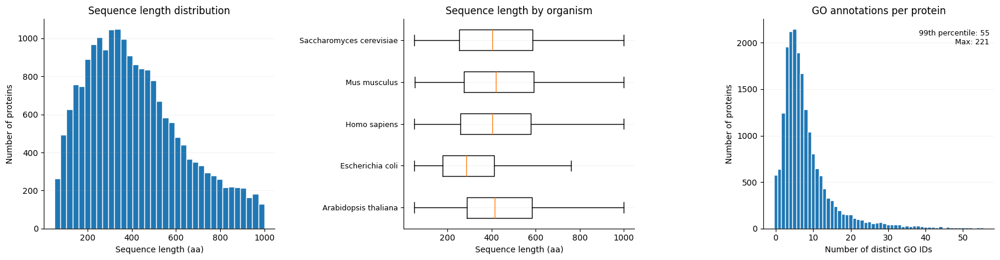

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(proteins["length"], bins=35, edgecolor="white")
axes[0].set(
    title="Sequence length distribution",
    xlabel="Sequence length (aa)",
    ylabel="Number of proteins",
)

organism_lengths = [
    group["length"].values
    for _, group in proteins.groupby("organism")
]
organism_names = [
    name.split(" (")[0]
    for name, _ in proteins.groupby("organism")
]

axes[1].boxplot(
    organism_lengths,
    tick_labels=organism_names,
    vert=False,
    showfliers=False,
)
axes[1].set(
    title="Sequence length by organism",
    xlabel="Sequence length (aa)",
)
axes[1].tick_params(axis="y", labelsize=9)

go_limit = int(np.percentile(protein_go_counts, 99))
go_counts_visible = np.asarray(protein_go_counts)
go_counts_visible = go_counts_visible[go_counts_visible <= go_limit]

axes[2].hist(
    go_counts_visible,
    bins=np.arange(go_limit + 2) - 0.5,
    edgecolor="white",
)
axes[2].set(
    title="GO annotations per protein",
    xlabel="Number of distinct GO IDs",
    ylabel="Number of proteins",
)

axes[2].text(
    0.98, 0.95,
    f"99th percentile: {go_limit}\n"
    f"Max: {max(protein_go_counts)}",
    transform=axes[2].transAxes,
    ha="right",
    va="top",
    fontsize=9,
)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.15)

plt.tight_layout(w_pad=3)
plt.show()

## 2. Sparse retrieval: BM25

Создаём **два независимых** индекса: BM25 по перекрывающимся аминокислотным 3-мерам и BM25 по словам аннотаций. Оба индекса содержат одни и те же ID белков, но используют разные признаки.

In [ ]:
def kmers(sequence):
    return [sequence[i:i + KMER] for i in range(max(0, len(sequence) - KMER + 1))]


def words(text):
    return re.findall(r'[a-z0-9]+', text.lower())


sequence_docs = [' '.join(kmers(s)) for s in proteins.sequence]
annotation_docs = [' '.join(words(s)) for s in proteins.annotation]
seq_tokenizer = Tokenizer(splitter=lambda s: s.split())
text_tokenizer = Tokenizer(splitter=lambda s: s.split())

seq_bm25 = bm25s.BM25(method='lucene')
seq_bm25.index(seq_tokenizer.tokenize(sequence_docs))
text_bm25 = bm25s.BM25(method='lucene')
text_bm25.index(text_tokenizer.tokenize(annotation_docs))
print('Два BM25-индекса готовы:', len(proteins), 'документов в каждом')

Tokenize texts:   0%|          | 0/19976 [00:00<?, ?it/s]

DEBUG:bm25s:Building index from token IDs


BM25S Count Tokens:   0%|          | 0/19976 [00:00<?, ?it/s]

BM25S Compute Scores:   0%|          | 0/19976 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/19976 [00:00<?, ?it/s]

DEBUG:bm25s:Building index from token IDs


BM25S Count Tokens:   0%|          | 0/19976 [00:00<?, ?it/s]

BM25S Compute Scores:   0%|          | 0/19976 [00:00<?, ?it/s]

Два BM25-индекса готовы: 19976 документов в каждом


## 3. Dense retrieval: ProTrek

Загружаем **официальную архитектуру и checkpoint** [ProTrek](https://github.com/westlake-repl/ProTrek). Используем только белковый и текстовый энкодеры. Для каждого белка вычисляем **два вектора**: последовательности и аннотации.

`CACHE_EMBEDDINGS=True` сохраняет собственные `.npy` внутри `/content/embeddings` и ускоряет повторный запуск **в том же runtime**. На компьютерах/в Colab студентов этих файлов заранее нет; первая попытка вычислит их самостоятельно. Это не подключение к Drive преподавателя.

In [ ]:
repo = Path('/content/ProTrek')
module_path = repo / 'model' / 'ProTrek' / 'protrek_trimodal_model.py'
if not module_path.exists():
    if repo.exists():
        raise RuntimeError('Папка ProTrek существует, но модуль модели не найден. Удалите неполную папку и перезапустите ячейку.')
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/westlake-repl/ProTrek.git', str(repo)], check=True)
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from model.ProTrek.protrek_trimodal_model import ProTrekTrimodalModel

# В inference-режиме не нужны тренировочные torchmetrics / optimizer.
ProTrekTrimodalModel.initialize_metrics = lambda self, stage: {}
ProTrekTrimodalModel.init_optimizers = lambda self: None

weights = Path(snapshot_download(repo_id=f'westlake-repl/ProTrek_{MODEL_SIZE}'))
protein_backbone = 'esm2_t12_35M_UR50D' if MODEL_SIZE == '35M' else 'esm2_t33_650M_UR50D'
structure_backbone = 'foldseek_t12_35M' if MODEL_SIZE == '35M' else 'foldseek_t30_150M'
model = ProTrekTrimodalModel(
    protein_config=str(weights / protein_backbone),
    text_config=str(weights / 'BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext'),
    structure_config=str(weights / structure_backbone),
    load_protein_pretrained=False,
    load_text_pretrained=False,
    from_checkpoint=str(weights / f'ProTrek_{MODEL_SIZE}.pt'),
).eval().to(DEVICE)
print('ProTrek готов:', DEVICE)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

.gitattributes: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/40.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

No lr_scheduler_kwargs provided. The default learning rate is 0.
No optimizer_kwargs provided. The default optimizer is AdamW.
Some weights of the model checkpoint were not used: ['1.model.esm.embeddings.position_ids', '2.model.embeddings.position_ids', '3.model.esm.embeddings.position_ids']
ProTrek готов: cuda


In [ ]:
@torch.inference_mode()
def encode(items, mode, batch_size=8):
    if mode not in ('protein', 'text'):
        raise ValueError('mode = protein/text')
    if not items:
        raise ValueError('Пустой список запросов')
    result = []
    for start in tqdm(range(0, len(items), batch_size), desc=f'Encoding {mode}'):
        batch = list(items[start:start + batch_size])
        embeddings = model.get_protein_repr(batch) if mode == 'protein' else model.get_text_repr(batch)
        result.append(embeddings.float().cpu().numpy())
    return np.ascontiguousarray(np.vstack(result), dtype='float32')


EMBEDDINGS_DIR = Path('/content/embeddings')
if CACHE_EMBEDDINGS:
    EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)

fingerprint = hashlib.sha256(
    proteins[['protein_id', 'sequence', 'annotation']].to_csv(index=False).encode('utf-8')
).hexdigest()[:12]


def load_or_encode(items, mode, batch_size):
    cache_path = EMBEDDINGS_DIR / f'protrek_{MODEL_SIZE}_{fingerprint}_{mode}.npy'
    if CACHE_EMBEDDINGS and cache_path.exists():
        stored = np.load(cache_path)
        if stored.ndim == 2 and stored.shape[0] == len(items):
            print('Кеш:', cache_path)
            return stored.astype('float32')
    stored = encode(items, mode, batch_size)
    if CACHE_EMBEDDINGS:
        np.save(cache_path, stored)
    return stored


sequence_embeddings = load_or_encode(proteins.sequence.tolist(), 'protein', batch_size=4)
annotation_embeddings = load_or_encode(proteins.annotation.tolist(), 'text', batch_size=16)
assert sequence_embeddings.shape == annotation_embeddings.shape
print('Embeddings:', sequence_embeddings.shape)

Encoding protein:   0%|          | 0/4994 [00:00<?, ?it/s]

Encoding text:   0%|          | 0/1249 [00:00<?, ?it/s]

Embeddings: (19976, 1024)


## 4. Exact dense search: FAISS

Нормализуем векторы по L2 и строим `IndexFlatIP`. Для нормализованных векторов inner product эквивалентен cosine similarity. Оба индекса точные: здесь **не** оцениваем качество ANN.

In [ ]:
protein_vectors = np.ascontiguousarray(sequence_embeddings.copy(), dtype='float32')
text_vectors = np.ascontiguousarray(annotation_embeddings.copy(), dtype='float32')
faiss.normalize_L2(protein_vectors)
faiss.normalize_L2(text_vectors)

protein_index = faiss.IndexFlatIP(protein_vectors.shape[1])
protein_index.add(protein_vectors)
text_index = faiss.IndexFlatIP(text_vectors.shape[1])
text_index.add(text_vectors)
assert protein_index.ntotal == text_index.ntotal == len(proteins)

scores, positions = protein_index.search(protein_vectors[:1], min(5, len(proteins)))
expected = np.argsort(-(protein_vectors @ protein_vectors[0]))[:len(positions[0])]

## 5. Единый поисковый интерфейс

`search(mode, query, method, top_k, filters)` поддерживает четыре имени режима:

- `sequence_to_sequence`: BM25 по k-мерам / ProTrek белок → белок;
- `annotation_to_annotation`: BM25 по словам / ProTrek текст → текст;
- `annotation_to_sequence`: BM25 по **аннотациям кандидатов** / ProTrek текст → белок;
- `go_to_sequence`: те же два поисковых маршрута, но запрос — **название GO-термина**, а не аннотация конкретного белка.

**Важно:** BM25 в режимах Annotation → Sequence и GO → Sequence не умеет сравнивать слова с аминокислотами. Это *текстовый baseline через связанную аннотацию белка*, а не прямой sequence search. Для запросов по ID из корпуса автоматически исключается сам белок. Фильтрация применяется **до** окончательного top-k.

In [ ]:
MODES = (
    'sequence_to_sequence', 'annotation_to_annotation',
    'annotation_to_sequence', 'go_to_sequence',
)
MODE_LABELS = {
    'sequence_to_sequence': 'Sequence → Sequence',
    'annotation_to_annotation': 'Annotation → Annotation',
    'annotation_to_sequence': 'Annotation → Sequence',
    'go_to_sequence': 'GO (Text) → Sequence',
}
METHODS = ('bm25', 'dense', 'hybrid')


def allowed_rows(filters=None):
    filters = filters or {}
    if set(filters) - {'organism', 'min_length', 'max_length'}:
        raise ValueError('Поддерживаются только organism, min_length, max_length')
    mask = np.ones(len(proteins), dtype=bool)
    if 'organism' in filters:
        mask &= proteins.organism.eq(filters['organism']).to_numpy()
    if 'min_length' in filters:
        mask &= proteins.length.ge(filters['min_length']).to_numpy()
    if 'max_length' in filters:
        mask &= proteins.length.le(filters['max_length']).to_numpy()
    return np.flatnonzero(mask)


def normalize_query(vector):
    vector = np.ascontiguousarray(vector.reshape(1, -1).copy(), dtype='float32')
    faiss.normalize_L2(vector)
    return vector


@lru_cache(maxsize=256)
def encoded_external_query(text, representation):
    return normalize_query(encode([text], representation, batch_size=1))


def resolve_query(mode, query):
    # GO — всегда буквальная строка, другие режимы допускают ID белка из корпуса.
    known_row = id_to_row.get(query) if mode != 'go_to_sequence' and isinstance(query, str) else None
    if known_row is None:
        return None, query
    if mode == 'sequence_to_sequence':
        return known_row, proteins.iloc[known_row].sequence
    return known_row, proteins.iloc[known_row].annotation


def basic_search(mode, query, method='dense', top_k=5, filters=None):
    if mode not in MODES or method not in ('bm25', 'dense') or top_k < 1:
        raise ValueError('Проверьте mode / method / top_k')
    known_row, query_text = resolve_query(mode, query)
    if not isinstance(query_text, str) or not query_text.strip():
        return []

    permitted = allowed_rows(filters)
    if known_row is not None:
        permitted = permitted[permitted != known_row]
    if not len(permitted):
        return []

    if method == 'bm25':
        is_seq = mode == 'sequence_to_sequence'
        index = seq_bm25 if is_seq else text_bm25
        tokenizer = seq_tokenizer if is_seq else text_tokenizer
        token_text = ' '.join(kmers(query_text) if is_seq else words(query_text))
        if not token_text:
            return []
        # При фильтрации нужно получить достаточно кандидатов до финального top_k.
        fetch_k = len(proteins) if filters else min(len(proteins), top_k + int(known_row is not None))
        rows, scores = index.retrieve(tokenizer.tokenize([token_text], update_vocab=False), k=fetch_k)
        permitted_set = set(permitted.tolist())
        pairs = [(int(row), float(score)) for row, score in zip(rows[0], scores[0])
                 if int(row) in permitted_set and score > 0][:top_k]
    else:
        protein_query = mode == 'sequence_to_sequence'
        target_is_text = mode == 'annotation_to_annotation'
        if known_row is not None:
            vectors = protein_vectors if protein_query else text_vectors
            q = vectors[known_row:known_row + 1]
        else:
            q = encoded_external_query(query_text, 'protein' if protein_query else 'text')
        target_vectors = text_vectors if target_is_text else protein_vectors
        index = text_index if target_is_text else protein_index
        if filters:
            scores = target_vectors[permitted] @ q[0]
            order = np.argsort(-scores)[:top_k]
            pairs = [(int(permitted[j]), float(scores[j])) for j in order]
        else:
            fetch_k = min(len(proteins), top_k + int(known_row is not None))
            scores, rows = index.search(q, fetch_k)
            pairs = [(int(row), float(score)) for row, score in zip(rows[0], scores[0])
                     if row >= 0 and row != known_row][:top_k]

    return [{
        'protein_id': proteins.iloc[row].protein_id,
        'rank': rank, 'score': round(score, 5), 'method': method,
        'organism': proteins.iloc[row].organism,
        'annotation': proteins.iloc[row].annotation,
    } for rank, (row, score) in enumerate(pairs, start=1)]

## 6. Hybrid retrieval: Reciprocal Rank Fusion (RRF)

Берём кандидатов из BM25 и ProTrek, объединяем **по ID** и сортируем по сумме

$$\operatorname{RRF}(d) = \sum_{j} \frac{1}{60 + \operatorname{rank}_j(d)}.$$

Score BM25 и cosine нельзя складывать напрямую — они имеют разные шкалы. RRF учитывает **порядок**, а не исходные оценки. На этапе слияния берём больше 50 кандидатов из каждой ветки, чтобы не ограничить Recall@50 искусственно.

In [ ]:
def rrf(rankings, top_k=5, c=RRF_K):
    scores = defaultdict(float)
    for hits in rankings:
        for rank, hit in enumerate(hits, 1):
            scores[hit['protein_id']] += 1.0 / (c + rank)
    ranked = sorted(scores, key=lambda pid: (-scores[pid], id_to_row.get(pid, 10**9)))
    return ranked[:top_k], dict(scores)


def search(mode, query, method='hybrid', top_k=5, filters=None):
    if method in ('bm25', 'dense'):
        return basic_search(mode, query, method, top_k, filters)
    if mode not in MODES or method != 'hybrid' or top_k < 1:
        raise ValueError('Проверьте mode / method / top_k')
    n_candidates = min(len(proteins), max(100, top_k * 3))
    sparse = basic_search(mode, query, 'bm25', n_candidates, filters)
    dense = basic_search(mode, query, 'dense', n_candidates, filters)
    ids, scores = rrf([sparse, dense], top_k=top_k)
    return [{
        'protein_id': pid, 'rank': rank, 'score': round(scores[pid], 5),
        'method': 'hybrid', 'organism': proteins.iloc[id_to_row[pid]].organism,
        'annotation': proteins.iloc[id_to_row[pid]].annotation,
    } for rank, pid in enumerate(ids, 1)]

## 7. Первые выдачи

У всех четырёх режимов один API. Просматриваем первые пять документов перед расчётом метрик. Для экспериментов ниже берём `top_k = 50`, но вывод не перегружаем.

In [ ]:
def show_results(hits):
    if not hits:
        print('Нет результатов')
        return
    frame = pd.DataFrame(hits)
    display(frame.style.format(escape='html').set_properties(subset=['annotation'], **{
        'white-space': 'normal', 'overflow-wrap': 'anywhere',
        'max-width': '440px', 'text-align': 'left',
    }).hide(axis='index'))

candidate_query_ids = [pid for pid in proteins.protein_id
                       if proteins.loc[id_to_row[pid], 'annotation'].strip()
                       and relevant_for_protein(pid)]
example_id = candidate_query_ids[0] if candidate_query_ids else proteins.iloc[0].protein_id
print('Пример белкового запроса:', example_id)
for mode in MODES[:3]:
    print('\n', MODE_LABELS[mode])
    for method in METHODS:
        print('  ', method)
        show_results(search(mode, example_id, method, top_k=5))

Пример белкового запроса: P66899

 Sequence → Sequence
   bm25


Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

protein_id,rank,score,method,organism,annotation
P15877,1,61.703340,bm25,Escherichia coli (strain K12),FUNCTION: GDH is probably involved in energy conservation rather than in sugar metabolism. {ECO:0000305|PubMed:8509415}.
P17426,2,60.830140,bm25,Mus musculus (Mouse),"FUNCTION: Component of the adaptor protein complex 2 (AP-2). Adaptor protein complexes function in protein transport via transport vesicles in different membrane traffic pathways. Adaptor protein complexes are vesicle coat components and appear to be involved in cargo selection and vesicle formation. AP-2 is involved in clathrin-dependent endocytosis in which cargo proteins are incorporated into vesicles surrounded by clathrin (clathrin-coated vesicles, CCVs) which are destined for fusion with the early endosome. The clathrin lattice serves as a mechanical scaffold but is itself unable to bind directly to membrane components. Clathrin-associated adaptor protein (AP) complexes which can bind directly to both the clathrin lattice and to the lipid and protein components of membranes are considered to be the major clathrin adaptors contributing the CCV formation. AP-2 also serves as a cargo receptor to selectively sort the membrane proteins involved in receptor-mediated endocytosis. AP-2 seems to play a role in the recycling of synaptic vesicle membranes from the presynaptic surface. AP-2 recognizes Y-X-X-[FILMV] (Y-X-X-Phi) and [ED]-X-X-X-L-[LI] endocytosis signal motifs within the cytosolic tails of transmembrane cargo molecules. AP-2 may also play a role in maintaining normal post-endocytic trafficking through the ARF6-regulated, non-clathrin pathway. The AP-2 alpha subunit binds polyphosphoinositide-containing lipids, positioning AP-2 on the membrane. During long-term potentiation in hippocampal neurons, AP-2 is responsible for the endocytosis of ADAM10 (PubMed:23676497). The AP-2 alpha subunit acts via its C-terminal appendage domain as a scaffolding platform for endocytic accessory proteins. The AP-2 alpha and AP-2 sigma subunits are thought to contribute to the recognition of the [ED]-X-X-X-L-[LI] motif (By similarity). {ECO:0000250, ECO:0000269|PubMed:14745134, ECO:0000269|PubMed:15473838, ECO:0000269|PubMed:23676497}."
P06972,3,60.093250,bm25,Escherichia coli (strain K12),"FUNCTION: Part of the ABC transporter complex FhuCDB involved in iron(3+)-hydroxamate import. Responsible for the translocation of the substrate across the membrane. {ECO:0000269|PubMed:1551849, ECO:0000269|PubMed:3020380, ECO:0000269|PubMed:34887516}."
P00927,4,59.924880,bm25,Saccharomyces cerevisiae (strain ATCC 204508 / S288c) (Baker's yeast),
P03959,5,59.606160,bm25,Escherichia coli (strain K12),"FUNCTION: Part of the high-affinity ATP-driven potassium transport (or Kdp) system, which catalyzes the hydrolysis of ATP coupled with the electrogenic transport of potassium into the cytoplasm (PubMed:23930894, PubMed:2849541, PubMed:8499455). This subunit binds the periplasmic potassium ions and delivers the ions to the membrane domain of KdpB through an intramembrane tunnel (PubMed:30478378, PubMed:34272288, PubMed:7896809). {ECO:0000269|PubMed:23930894, ECO:0000269|PubMed:2849541, ECO:0000269|PubMed:30478378, ECO:0000269|PubMed:34272288, ECO:0000269|PubMed:7896809, ECO:0000269|PubMed:8499455}."


   dense


protein_id,rank,score,method,organism,annotation
P0AEH3,1,0.778820,dense,Escherichia coli (strain K12),
P16703,2,0.773370,dense,Escherichia coli (strain K12),FUNCTION: Two cysteine synthase enzymes are found. Both catalyze the same reaction. Cysteine synthase B can also use thiosulfate in place of sulfide to give cysteine thiosulfonate as a product.
P0AGF6,3,0.768360,dense,Escherichia coli (strain K12),"FUNCTION: Catalyzes the anaerobic formation of alpha-ketobutyrate and ammonia from threonine in a two-step reaction. The first step involved a dehydration of threonine and a production of enamine intermediates (aminocrotonate), which tautomerizes to its imine form (iminobutyrate). Both intermediates are unstable and short-lived. The second step is the nonenzymatic hydrolysis of the enamine/imine intermediates to form 2-ketobutyrate and free ammonia. In the low water environment of the cell, the second step is accelerated by RidA. TdcB also dehydrates serine to yield pyruvate via analogous enamine/imine intermediates. {ECO:0000269|PubMed:10388709, ECO:0000269|PubMed:13405870, ECO:0000269|PubMed:15390404}."
P76319,4,0.748830,dense,Escherichia coli (strain K12),
P77218,5,0.748110,dense,Escherichia coli (strain K12),FUNCTION: When expressed independently of the eut operon it can restore growth to a double pta-acs deletion mutant. {ECO:0000269|PubMed:21046341}.


... (20 outputs left out)

   hybrid


Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

protein_id,rank,score,method,organism,annotation
P00934,1,0.029760,hybrid,Escherichia coli (strain K12),"FUNCTION: Catalyzes the gamma-elimination of phosphate from L-phosphohomoserine and the beta-addition of water to produce L-threonine. To a lesser extent, is able to slowly catalyze the deamination of L-threonine into alpha-ketobutyrate and that of L-serine and 3-chloroalanine into pyruvate. Is also able to rapidly convert vinylglycine to threonine, which proves that the pyridoxal p-quinonoid of vinylglycine is an intermediate in the TS reaction. {ECO:0000269|PubMed:7907888}."
P03813,2,0.028400,hybrid,Escherichia coli (strain K12),"FUNCTION: Amino-acid racemase able to utilize a broad range of substrates. Highest activity is observed with L-homoserine and D-homoserine. Has tenfold lower activity against L-methionine, L-leucine, L-valine and L-histidine. Has low activity with L-norvaline, L-asparagine, D-methionine, L-aminobutyric acid, L-isoleucine, L-serine, L-norleucine, L-alanine, L-glutamine, LL-diaminopimelic acid and L-phenylalanine. Has no activity against ten L-amino acids (Thr, Glu, Asp, Arg, Lys, Tyr, Trp, Orn, Cit and Aad) (PubMed:28894939). D-amino acids might be used as components of peptidoglycan and/or be involved in peptidoglycan metabolism and remodeling (PubMed:28894939). {ECO:0000269|PubMed:28894939}."
P36007,3,0.027500,hybrid,Saccharomyces cerevisiae (strain ATCC 204508 / S288c) (Baker's yeast),"FUNCTION: Catalyzes the deamination of L-threo-3-hydroxyaspartate to oxaloacetate and ammonia. Shows a high specificity towards L-threo-3-hydroxyaspartate as other 3-hydroxyaminoacids, i.e. D,L-erythro- and D-threo-3-hydroxyaspartate, D-threonine, L-threonine, D,L-allothreonine, D-serine, and L-serine, are not substrates for this enzyme. Exhibits no detectable serine racemase activity. Is responsible for the 3-hydroxyaspartate resistance of S.cerevisiae, and thus may be involved in the detoxification of naturally occurring 3-hydroxyaspartate. {ECO:0000269|PubMed:12951240}."
P29012,4,0.026330,hybrid,Escherichia coli (strain K12),FUNCTION: Isomerizes L-alanine to D-alanine which is then oxidized to pyruvate by DadA. {ECO:0000250}.
P0ACV6,5,0.025920,hybrid,Escherichia coli (strain K12),"FUNCTION: Involved in muropeptide degradation. Catalyzes the hydrolysis of the gamma-D-glutamyl-diaminopimelic acid (gamma-D-Glu-Dap) amide bond in the murein tripeptide L-alanyl-gamma-D-glutamyl-meso-diaminopimelic acid, leading to the formation of L-Ala-gamma-D-Glu and Dap (PubMed:12511517, PubMed:22970852). Has weak activity with L-Ala-gamma-D-Glu-L-Lys, MurNAc-tripeptide and gamma-D-Glu-meso-Dap (PubMed:22970852). Cannot hydrolyze murein tetrapeptide (PubMed:22970852). {ECO:0000269|PubMed:12511517, ECO:0000269|PubMed:22970852}."


## 8. Метрики для k = 5, 10, 50

- **Precision@k:** доля релевантных среди первых k позиций (недостающие позиции считаем нерелевантными).
- **Recall@k:** доля **всех известных** релевантных ID, попавших в top-k.
- **nDCG@k:** качество ранжирования с более высоким весом первых позиций (бинарные метки).
- **RR@k:** обратное место первого релевантного ID; **MRR@k** — среднее RR по запросам.
- **Hit@k:** нашёлся ли хотя бы один релевантный ID.

Список для каждого запроса получаем **один раз до max(k)** и считаем метрики для всех трёх k. Запросы без релевантных документов исключаем из среднего и отдельно показываем их количество.

In [ ]:
def evaluate_ranking(found, relevant, k_values=K_VALUES):
    relevant = set(relevant)
    if not relevant:
        return None
    if len(found) != len(set(found)):
        raise ValueError('Выдача содержит повторяющиеся protein_id')
    result = {}
    for k in k_values:
        hits = np.array([pid in relevant for pid in found[:k]], dtype=float)
        hits = np.pad(hits, (0, max(0, k - len(hits))))
        discounts = 1 / np.log2(np.arange(2, k + 2))
        dcg = float((hits * discounts).sum())
        idcg = float(discounts[:min(k, len(relevant))].sum())
        first = np.flatnonzero(hits)
        result.update({
            f'nDCG@{k}': dcg / idcg,
            f'Precision@{k}': float(hits.sum() / k),
            f'Recall@{k}': float(hits.sum() / len(relevant)),
            f'RR@{k}': float(1.0 / (first[0] + 1)) if len(first) else 0.0,
            f'Hit@{k}': int(bool(hits.any())),
        })
    return result

In [ ]:
def evaluate_mode(mode, benchmark):
    """benchmark: список (query_string, set(relevant_IDs))."""
    rows = []
    for query, relevant in tqdm(benchmark, desc=MODE_LABELS[mode]):
        for method in METHODS:
            hits = search(mode, query, method=method, top_k=max(K_VALUES))
            metrics = evaluate_ranking([h['protein_id'] for h in hits], relevant)
            if metrics is not None:
                rows.append({'mode': mode, 'query': query, 'method': method,
                             'relevant_n': len(relevant), **metrics})
    return pd.DataFrame(rows)


def summarize(frame):
    if frame.empty:
        return pd.DataFrame()
    rows = []
    for (mode, method), group in frame.groupby(['mode', 'method'], sort=False):
        for k in K_VALUES:
            rows.append({
                'mode': MODE_LABELS[mode], 'method': method, 'k': k,
                'queries': len(group),
                'nDCG': group[f'nDCG@{k}'].mean(),
                'Precision': group[f'Precision@{k}'].mean(),
                'Recall': group[f'Recall@{k}'].mean(),
                'MRR': group[f'RR@{k}'].mean(),
                'Hit': group[f'Hit@{k}'].mean(),
            })
    return pd.DataFrame(rows)


def show_summary(frame):
    if frame.empty:
        print('Недостаточно размеченных запросов для оценки')
    else:
        display(frame.style.format({
            'nDCG': '{:.3f}', 'Precision': '{:.3f}', 'Recall': '{:.3f}',
            'MRR': '{:.3f}', 'Hit': '{:.3f}',
        }).hide(axis='index'))

### Общий набор белковых запросов для экспериментов 1–3

Берём только белки, у которых есть **текстовая аннотация** и хотя бы **один другой** белок с общим GO ID. Это позволяет использовать **одни и те же запросы** для трёх режимов и не объяснять разницу в качестве только различиями в подборе запросов.

In [ ]:
query_ids = [
    pid for pid in proteins.protein_id
    if proteins.iloc[id_to_row[pid]].annotation.strip() and relevant_for_protein(pid)
]
rng = np.random.default_rng(RANDOM_STATE)
if len(query_ids) > EVAL_N:
    query_ids = rng.choice(query_ids, size=EVAL_N, replace=False).tolist()

protein_benchmark = [(pid, relevant_for_protein(pid)) for pid in query_ids]
print('Белковых запросов для режимов 1–3:', len(protein_benchmark))
if not protein_benchmark:
    print('Недостаточно GO-разметки: увеличьте MAX_ROWS или проверьте столбцы GO в датасете.')
else:
    print('Размеры эталонных множеств (min / median / max):',
          min(len(relevant) for _, relevant in protein_benchmark),
          np.median([len(relevant) for _, relevant in protein_benchmark]),
          max(len(relevant) for _, relevant in protein_benchmark))

Белковых запросов для режимов 1–3: 100
Размеры эталонных множеств (min / median / max): 2 557.5 5278


## Эксперимент 1. Sequence → Sequence

**Проверяем:** находят ли похожие по GO белки классические 3-меры и ProTrek sequence encoder. Запрос — последовательность белка из корпуса; собственный ID исключён из результатов.

In [ ]:
sequence_eval = evaluate_mode('sequence_to_sequence', protein_benchmark)
show_summary(summarize(sequence_eval))

Sequence → Sequence:   0%|          | 0/100 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

... (392 outputs left out)

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

mode,method,k,queries,nDCG,Precision,Recall,MRR,Hit
Sequence → Sequence,bm25,5,100,0.365,0.332,0.010,0.543,0.640
Sequence → Sequence,bm25,10,100,0.312,0.273,0.011,0.553,0.710
Sequence → Sequence,bm25,50,100,0.208,0.164,0.017,0.560,0.860
Sequence → Sequence,dense,5,100,0.618,0.598,0.017,0.762,0.860
Sequence → Sequence,dense,10,100,0.557,0.519,0.021,0.765,0.880
Sequence → Sequence,dense,50,100,0.404,0.345,0.040,0.770,0.970
Sequence → Sequence,hybrid,5,100,0.525,0.494,0.013,0.711,0.820
Sequence → Sequence,hybrid,10,100,0.469,0.429,0.018,0.723,0.900
Sequence → Sequence,hybrid,50,100,0.343,0.290,0.036,0.726,0.950


**Обсудите:** почему совпадение многих k-меров не гарантирует совпадения функций? Можно ли ожидать выигрыша dense-подхода для менее похожих последовательностей?

## Эксперимент 2. Annotation → Annotation

**Проверяем:** насколько хорошо поиск по описаниям функций восстанавливает соседей по GO. Запрос — **полная аннотация одного белка**, кандидаты — аннотации других белков. Критерий релевантности по-прежнему общий GO ID (не точное совпадение текста).

In [ ]:
annotation_eval = evaluate_mode('annotation_to_annotation', protein_benchmark)
show_summary(summarize(annotation_eval))

Annotation → Annotation:   0%|          | 0/100 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

... (392 outputs left out)

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

mode,method,k,queries,nDCG,Precision,Recall,MRR,Hit
Annotation → Annotation,bm25,5,100,0.716,0.686,0.024,0.843,0.900
Annotation → Annotation,bm25,10,100,0.649,0.602,0.032,0.854,0.980
Annotation → Annotation,bm25,50,100,0.519,0.455,0.077,0.854,0.990
Annotation → Annotation,dense,5,100,0.770,0.730,0.032,0.920,0.960
Annotation → Annotation,dense,10,100,0.733,0.690,0.044,0.923,0.990
Annotation → Annotation,dense,50,100,0.589,0.515,0.086,0.924,1.000
Annotation → Annotation,hybrid,5,100,0.790,0.760,0.030,0.924,0.950
Annotation → Annotation,hybrid,10,100,0.738,0.695,0.046,0.928,0.980
Annotation → Annotation,hybrid,50,100,0.599,0.526,0.093,0.929,1.000


**Обсудите:** почему лексический BM25 может хорошо работать, когда запрос и документы описывают функцию словами из одного словаря? А что происходит с синонимами?

## Эксперимент 3. Annotation → Sequence

**Проверяем кросс-модальность:** текстовое описание функции используется как запрос, но dense-кандидаты ранжируются по **эмбеддингам аминокислотных последовательностей**. BM25 здесь — поиск через текстовые аннотации кандидатов как baseline. И запросы, и эталон **в точности те же**, что в эксперименте 2.

In [ ]:
annotation_sequence_eval = evaluate_mode('annotation_to_sequence', protein_benchmark)
show_summary(summarize(annotation_sequence_eval))

Annotation → Sequence:   0%|          | 0/100 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

... (392 outputs left out)

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

mode,method,k,queries,nDCG,Precision,Recall,MRR,Hit
Annotation → Sequence,bm25,5,100,0.716,0.686,0.024,0.843,0.900
Annotation → Sequence,bm25,10,100,0.649,0.602,0.032,0.854,0.980
Annotation → Sequence,bm25,50,100,0.519,0.455,0.077,0.854,0.990
Annotation → Sequence,dense,5,100,0.694,0.664,0.024,0.840,0.910
Annotation → Sequence,dense,10,100,0.641,0.599,0.032,0.844,0.940
Annotation → Sequence,dense,50,100,0.535,0.476,0.075,0.848,1.000
Annotation → Sequence,hybrid,5,100,0.780,0.748,0.029,0.909,0.950
Annotation → Sequence,hybrid,10,100,0.745,0.705,0.048,0.912,0.970
Annotation → Sequence,hybrid,50,100,0.590,0.511,0.092,0.914,1.000


**Обсудите:** сравните dense результаты экспериментов 2 и 3. В каком случае текстовому энкодеру нужно решить более сложную задачу? Почему BM25 для них получается одинаковым?

## Эксперимент 4. GO (Text) → Sequence

**Теперь вводим запросы другого типа.** Берём *названия GO-терминов*, а релевантные ID определяем по **GO ID**, не по похожести названия и не по ответу поисковика.

Здесь важно отделить формулировку запроса от эталона: строка `DNA repair` используется для поиска, а membership `GO:...` — для подсчёта метрик. Результаты несопоставимы напрямую с первыми тремя режимами как абсолютно равные задачи, потому что запросы и размеры эталонных множеств другие.

In [ ]:
go_candidates = [
    (gid, name, members) for gid, members in go_members.items()
    for name in [go_names.get(gid, '')]
    if name and GO_MIN_MEMBERS <= len(members) <= max(20, len(proteins) // 5)
]
# По аналогии с исходным ноутбуком: самые распространённые из допустимых GO.
go_candidates.sort(key=lambda item: (-len(item[2]), item[0]))
go_candidates = go_candidates[:GO_EVAL_N]
go_benchmark = [(name, members) for gid, name, members in go_candidates]

print('GO-запросов:', len(go_benchmark))
display(pd.DataFrame([{'GO ID': gid, 'Text query': name, 'relevant': len(members)}
                      for gid, name, members in go_candidates[:10]]))

GO-запросов: 50


,GO ID,Text query,relevant
0,GO:0042802,identical protein binding,1901
1,GO:0005524,ATP binding,1729
2,GO:0003700,DNA-binding transcription factor activity,1015
3,GO:0003677,DNA binding,1013
4,GO:0006355,regulation of DNA-templated transcription,1000
5,GO:0045944,positive regulation of transcription by RNA po...,984
6,GO:0042803,protein homodimerization activity,951
7,GO:0006357,regulation of transcription by RNA polymerase II,916
8,GO:0008270,zinc ion binding,857
9,GO:0003723,RNA binding,785


In [ ]:
go_eval = evaluate_mode('go_to_sequence', go_benchmark)
show_summary(summarize(go_eval))

GO (Text) → Sequence:   0%|          | 0/50 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Encoding text:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

... (242 outputs left out)

Encoding text:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

mode,method,k,queries,nDCG,Precision,Recall,MRR,Hit
GO (Text) → Sequence,bm25,5,50,0.256,0.252,0.003,0.359,0.520
GO (Text) → Sequence,bm25,10,50,0.267,0.270,0.006,0.378,0.660
GO (Text) → Sequence,bm25,50,50,0.274,0.274,0.030,0.390,0.900
GO (Text) → Sequence,dense,5,50,0.748,0.752,0.008,0.818,0.940
GO (Text) → Sequence,dense,10,50,0.735,0.732,0.016,0.827,1.000
GO (Text) → Sequence,dense,50,50,0.683,0.668,0.072,0.827,1.000
GO (Text) → Sequence,hybrid,5,50,0.570,0.564,0.006,0.733,0.940
GO (Text) → Sequence,hybrid,10,50,0.568,0.562,0.013,0.739,0.980
GO (Text) → Sequence,hybrid,50,50,0.523,0.510,0.056,0.741,1.000


## 9. Сравнение всех экспериментов

Сначала смотрим таблицы по каждому режиму, затем сравним **влияние k** на качество. Для первых трёх режимов набор запросов один; для GO-текста — отдельный. Это нужно учитывать при интерпретации графика.

In [ ]:
parts = [frame for frame in (sequence_eval, annotation_eval, annotation_sequence_eval, go_eval)
         if not frame.empty]
all_eval = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
summary_all = summarize(all_eval)
show_summary(summary_all)

mode,method,k,queries,nDCG,Precision,Recall,MRR,Hit
Sequence → Sequence,bm25,5,100,0.365,0.332,0.010,0.543,0.640
Sequence → Sequence,bm25,10,100,0.312,0.273,0.011,0.553,0.710
Sequence → Sequence,bm25,50,100,0.208,0.164,0.017,0.560,0.860
Sequence → Sequence,dense,5,100,0.618,0.598,0.017,0.762,0.860
Sequence → Sequence,dense,10,100,0.557,0.519,0.021,0.765,0.880
Sequence → Sequence,dense,50,100,0.404,0.345,0.040,0.770,0.970
Sequence → Sequence,hybrid,5,100,0.525,0.494,0.013,0.711,0.820
Sequence → Sequence,hybrid,10,100,0.469,0.429,0.018,0.723,0.900
Sequence → Sequence,hybrid,50,100,0.343,0.290,0.036,0.726,0.950
Annotation → Annotation,bm25,5,100,0.716,0.686,0.024,0.843,0.900


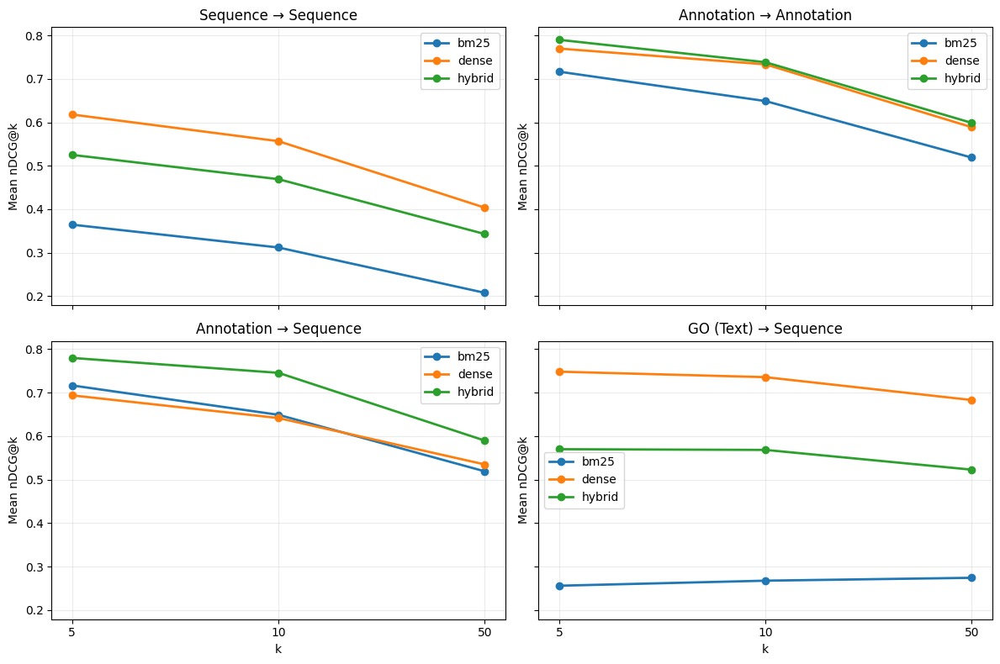

In [ ]:
if not summary_all.empty:
    fig, axes = plt.subplots(
        2, 2, figsize=(12, 8),
        sharex=True, sharey=True
    )

    x = np.arange(len(K_VALUES))

    for ax, mode in zip(axes.flat, MODES):
        subset = summary_all[summary_all['mode'] == MODE_LABELS[mode]]

        for method in METHODS:
            series = subset[subset.method == method].set_index('k')
            y = series.reindex(K_VALUES)['nDCG']

            ax.plot(x, y, marker='o', linewidth=2, label=method)

        ax.set(
            title=MODE_LABELS[mode],
            ylabel='Mean nDCG@k',
            xticks=x,
            xticklabels=K_VALUES,
        )
        ax.grid(alpha=0.25)
        ax.legend()

    for ax in axes[-1]:
        ax.set_xlabel('k')

    plt.tight_layout()
    plt.show()

### Анализ запросов, на которых dense хуже или лучше BM25

Рассмотрим **разность nDCG@10** для первых трёх экспериментов. Отрицательные значения означают выигрыш BM25, положительные — dense. Отдельные запросы полезнее средних значений: их можно затем проверить вручную.

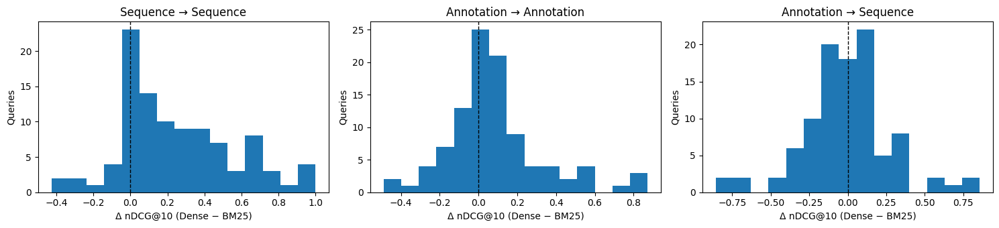

In [ ]:
DELTA_K = 10
if not all_eval.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    for ax, mode in zip(axes, MODES[:3]):
        subset = all_eval[all_eval['mode'] == mode]
        if subset.empty:
            ax.set(title=MODE_LABELS[mode]); continue
        wide = subset.pivot(index='query', columns='method', values=f'nDCG@{DELTA_K}')
        delta = wide['dense'] - wide['bm25']
        ax.hist(delta.dropna(), bins=15)
        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set(title=MODE_LABELS[mode], xlabel=f'Δ nDCG@{DELTA_K} (Dense − BM25)', ylabel='Queries')
    plt.tight_layout()
    plt.show()

## 10. Функции для будущего LLM-агента

Агенту достаточно выбрать модальность запроса, способ поиска и фильтры — детали FAISS, BM25 и RRF скрыты за единым API. В этом практикуме **нет LLM**: мы только готовим поисковые инструменты.

In [ ]:
def search_by_sequence(protein_id_or_sequence, top_k=5, method='hybrid', filters=None):
    return search('sequence_to_sequence', protein_id_or_sequence, method, top_k, filters)


def search_by_annotation(protein_id_or_text, top_k=5, method='hybrid', filters=None):
    return search('annotation_to_annotation', protein_id_or_text, method, top_k, filters)


def search_sequences_by_annotation(protein_id_or_text, top_k=5, method='hybrid', filters=None):
    return search('annotation_to_sequence', protein_id_or_text, method, top_k, filters)


def search_proteins_by_go_text(go_text, top_k=5, method='hybrid', filters=None):
    return search('go_to_sequence', go_text, method, top_k, filters)


def get_protein(protein_id):
    return proteins.iloc[id_to_row[protein_id]].to_dict()

if go_candidates:
    seeds = search_proteins_by_go_text(go_candidates[0][1], top_k=2)
    for seed in seeds:
        print('Seed:', seed['protein_id'])
        show_results(search_by_sequence(seed['protein_id'], top_k=3))

Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

Seed: Q96D96


Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

protein_id,rank,score,method,organism,annotation
Q3U2S8,1,0.032790,hybrid,Mus musculus (Mouse),"FUNCTION: Voltage-gated proton-selective channel that conducts outward proton currents in response to intracellular acidification. Lacks a canonical ion-channel pore domain and mediates proton permeability via its voltage sensor domain (PubMed:16556803, PubMed:19805063, PubMed:22569364, PubMed:23165764, PubMed:24584463). Provides for proton efflux that compensates for electron charge generated by NADPH oxidase activity either in the extracellular or phagosomal compartments, thus enabling the production of high levels of bactericidal reactive oxygen species during the respiratory burst (PubMed:19805063, PubMed:20026664, PubMed:24415791). Opens when the pH of airway surface liquid exceeds 7 and contributes to respiratory epithelial acid secretion to maintain pH in the mucosa (By similarity). {ECO:0000250|UniProtKB:Q96D96, ECO:0000269|PubMed:16556803, ECO:0000269|PubMed:19805063, ECO:0000269|PubMed:20026664, ECO:0000269|PubMed:22569364, ECO:0000269|PubMed:23165764, ECO:0000269|PubMed:24415791, ECO:0000269|PubMed:24584463}."
Q3ZAS0,2,0.020070,hybrid,Mus musculus (Mouse),"FUNCTION: Plasma membrane Na(+)/H(+) antiporter (PubMed:14962844, PubMed:16690903). Mediates the electroneutral exchange of intracellular H(+) ions for extracellular Na(+) (PubMed:14962844). Major apical Na(+)/H(+) exchanger in the base of the colonic crypt (PubMed:14962844, PubMed:16690903). Controls in the colonic crypt intracellular pH (pHi) to direct colonic epithelial cell differentiation into the absorptive enterocyte lineage at the expense of the secretory lineage (PubMed:14962844, PubMed:34985202). {ECO:0000269|PubMed:14962844, ECO:0000269|PubMed:16690903, ECO:0000269|PubMed:34985202}."
P59044,3,0.016130,hybrid,Homo sapiens (Human),"FUNCTION: Acts as the sensor component of the NLRP6 inflammasome, which mediates inflammasome activation in response to various pathogen-associated signals, leading to maturation and secretion of IL1B and IL18 (PubMed:30392956, PubMed:34678144). Inflammasomes are supramolecular complexes that assemble in the cytosol in response to pathogens and other damage-associated signals and play critical roles in innate immunity and inflammation (PubMed:30674671). Acts as a recognition receptor (PRR): recognizes and binds specific pathogens and other damage-associated signals, such as lipoteichoic acid (LTA), a cell-wall component of Gram-positive bacteria, or double stranded RNA (dsRNA) (PubMed:30392956, PubMed:33377178, PubMed:34678144). May also recognize and bind lipopolysaccharide (LPS), a major component of the outer membrane of Gram-negative bacteria; however, LPS is probably not a major activator of the NLRP6 inflammasome (PubMed:31932628, PubMed:34678144). Following LTA- or dsRNA-binding, NLRP6 undergoes liquid-liquid phase separation (LLPS), enhancing multivalent interactions, an essential step for the formation of the NLRP6 inflammasome polymeric complex (PubMed:34678144). The NLRP6 inflammasome acts by promoting recruitment of effector pro-inflammatory caspases (CASP1 and/or CASP4) that catalyze maturation and secretion of IL1B and IL18 in the extracellular milieu (PubMed:12387869, PubMed:30392956, PubMed:30674671, PubMed:34678144). The NLRP6 inflammasome plays a central role in the maintenance of epithelial integrity and host defense against microbial infections in the intestine (PubMed:30392956). Required to restrict infection against Gram-positive bacteria by recognizing lipoteichoic acid (LTA), leading to recruitment of CASP4 and CASP1, and subsequent maturation and secretion of IL1B and IL18 (PubMed:30392956, PubMed:33377178). Involved in intestinal antiviral innate immunity together with DHX15: recognizes and binds viral dsRNA to restrict infection by enteric viruses through the interferon pathway and GSDMD-dependent release of IL18 (PubMed:34161762, PubMed:34678144). Required to prevent infection by the apicomplexan parasite 

Seed: P38165


Tokenize texts:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

protein_id,rank,score,method,organism,annotation
P18494,1,0.028300,hybrid,Saccharomyces cerevisiae (strain ATCC 204508 / S288c) (Baker's yeast),"FUNCTION: Positive nitrogen regulatory protein. Required for the activation of transcription of a number of genes (including the allantoin pathway genes) in response to the replacement of glutamine by glutamate as source of nitrogen. Binds the nitrogen upstream activation sequence of GLN1, the gene encoding glutamine synthetase. URE2 may catalytically inactivate GLN3 in response to an increase in the intracellular concentration of glutamine."
P43574,2,0.024850,hybrid,Saccharomyces cerevisiae (strain ATCC 204508 / S288c) (Baker's yeast),FUNCTION: Positive regulator of multiple nitrogen catabolic genes.
P15806,3,0.021420,hybrid,Mus musculus (Mouse),"FUNCTION: Transcriptional regulator involved in the initiation of neuronal differentiation and mesenchymal to epithelial transition (PubMed:15226298, PubMed:18214987). Heterodimers between TCF3 and tissue-specific basic helix-loop-helix (bHLH) proteins play major roles in determining tissue-specific cell fate during embryogenesis, like muscle or early B-cell differentiation (PubMed:18214987). Together with TCF15, required for the mesenchymal to epithelial transition (PubMed:11309385, PubMed:15226298). Dimers bind DNA on E-box motifs: 5'-CANNTG-3' (PubMed:15226298, PubMed:18214987, PubMed:30426815). Binds to the kappa-E2 site in the kappa immunoglobulin gene enhancer (By similarity). Binds to IEB1 and IEB2, which are short DNA sequences in the insulin gene transcription control region (PubMed:2181401). {ECO:0000250|UniProtKB:P15923, ECO:0000269|PubMed:11309385, ECO:0000269|PubMed:15226298, ECO:0000269|PubMed:18214987, ECO:0000269|PubMed:2181401}.; FUNCTION: [Isoform E47]: Facilitates ATOH7 binding to DNA at the consensus sequence 5'-CAGGTG-3', and positively regulates transcriptional activity. {ECO:0000250|UniProtKB:P15923}."
